# ДЗ №2. Анализ поездок
### Выполнил: Лёвин В.А.
### Группа: ИУ6-54Б

## Подготовка

Читаем пять CSV Citi Bike за апрель 2026 года один раз. Таблицы считаем через Spark DataFrame API. Карты сохраняем в `output/`.

In [1]:
import os
import sys

import folium
import geopandas as gpd
import matplotlib.pyplot as plt
from folium.plugins import HeatMapWithTime
from IPython.display import display
from pyspark import SparkConf
from pyspark.sql import SparkSession, functions as F
from shapely.geometry import Point

conf = SparkConf().setMaster("local[2]").setAppName("HW2-CitiBike")
spark = SparkSession.builder.config(conf=conf).getOrCreate()
spark.sparkContext.pythonExec = sys.executable

trips = (
    spark.read.csv("*citibike-tripdata*.csv", header=True)
    .select("start_station_id", "start_station_name", "start_lat", "start_lng",
            "end_station_id", "end_station_name", "end_lat", "end_lng",
            "started_at", "ended_at")
    .cache()
)
os.makedirs("output", exist_ok=True)

26/11/28 21:59:39 WARN Utils: Your hostname, MacBook-Air-mac-4.local resolves to a loopback address: 127.0.0.1; using 192.168.0.116 instead (on interface en0)
26/11/28 21:59:39 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/28 21:59:40 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


## Задание 1. Станции и городские зоны

In [2]:
zones_map = gpd.read_file("data/nyc_zones.geojson")
zone_shapes = list(zip(zones_map["locationid"], zones_map.geometry))
zones = (
    spark.createDataFrame(zones_map[["locationid", "zone", "borough"]])
    .toDF("zone_id", "zone_name", "borough")
    .dropDuplicates(["zone_id"])
)

### 1. Количество отправлений и прибытий по станциям

Объединяем отправления и прибытия, суммируем по ID станции

In [3]:
starts = trips.selectExpr(
    "trim(start_station_id) as station_id", "start_station_name as station_name",
    "cast(start_lat as double) as latitude", "cast(start_lng as double) as longitude",
    "1 as starts", "0 as ends"
)
ends = trips.selectExpr(
    "trim(end_station_id) as station_id", "end_station_name as station_name",
    "cast(end_lat as double) as latitude", "cast(end_lng as double) as longitude",
    "0 as starts", "1 as ends"
)
events = starts.unionByName(ends)
valid_coordinates = F.expr("""
    latitude BETWEEN -90 AND 90
    AND longitude BETWEEN -180 AND 180
    AND latitude != 0
    AND longitude != 0
""")

station_counts = (
    events.filter("station_id != ''")
    .groupBy("station_id")
    .agg(
        F.first("station_name", ignorenulls=True).alias("station_name"),
        F.sum("starts").alias("starts"), F.sum("ends").alias("ends"),
        F.round(F.avg(F.when(valid_coordinates, F.col("latitude"))), 6).alias("latitude"),
        F.round(F.avg(F.when(valid_coordinates, F.col("longitude"))), 6).alias("longitude")
    )
    .cache()
)

station_table = station_counts.select("station_id", "station_name", "starts", "ends")
station_table.orderBy(F.desc("starts"), "station_id").show(10)

+----------+--------------------+------+-----+
|station_id|        station_name|starts| ends|
+----------+--------------------+------+-----+
|   6140.05|     W 21 St & 6 Ave| 14539|14567|
|   6233.04|Pier 61 at Chelse...| 13480|13505|
|   6492.08|     9 Ave & W 33 St| 12003|12033|
|   6331.01|     W 31 St & 7 Ave| 11683|11733|
|   5980.10|  E 17 St & Broadway| 11505|11582|
|   6098.10|  Broadway & E 21 St| 11414| 3097|
|   5788.13|Lafayette St & E ...| 11281|11373|
|   6912.01|7 Ave & Central P...| 10958|10892|
|   5905.14|University Pl & E...| 10957|11042|
|   5905.12|  Broadway & E 14 St| 10907|10975|
+----------+--------------------+------+-----+
only showing top 10 rows



### 2. Сопоставление станций с зонами и суммы по зонам

Для станции выбираем первую зону, содержащую точку `(долгота, широта)`. Суммируем отправления и прибытия по коду зоны. Станции вне полигонов в суммы зон не входят.

В выводе — 10 соответствий станции и зоны, затем 10 зон с суммами отправлений и прибытий.

In [4]:
def find_zone(longitude, latitude):
    if longitude is None or latitude is None:
        return None
    point = Point(longitude, latitude)
    for zone_id, polygon in zone_shapes:
        if polygon.covers(point):
            return zone_id
    return None

zone_for_point = F.udf(find_zone, "string")
stations = (
    station_counts.withColumn("zone_id", zone_for_point("longitude", "latitude"))
    .join(zones, "zone_id", "left")
)

zone_counts = stations.groupBy("zone_id").sum("starts", "ends")
zone_counts = zone_counts.toDF("zone_id", "starts", "ends")
zone_counts = zones.join(zone_counts, "zone_id", "left").fillna(0).cache()

stations.select("station_id", "station_name", "zone_id", "zone_name").show(10)
zone_counts.show(10)

+----------+--------------------+-------+--------------------+
|station_id|        station_name|zone_id|           zone_name|
+----------+--------------------+-------+--------------------+
|   5902.07|Eagle St & Manhat...|    112|          Greenpoint|
|   7790.04|Lenox Ave & W 133 St|     42|Central Harlem North|
|   7722.06|E 141 St & St Ann...|    168|Mott Haven/Port M...|
|   3394.03|McDonald Ave & Va...|    111| Green-Wood Cemetery|
|   4157.10|Bergen St & Vande...|    189|    Prospect Heights|
|   4677.06|Montague St & Cli...|     33|    Brooklyn Heights|
|   6542.05|      99 St & 35 Ave|    173|        North Corona|
|   5922.08| Bank St & Hudson St|    158|Meatpacking/West ...|
|   8049.05|Edgecombe Ave & W...|    116|    Hamilton Heights|
|   6346.07|Warren St & Roose...|    129|     Jackson Heights|
+----------+--------------------+-------+--------------------+
only showing top 10 rows



+-------+--------------------+---------+------+-----+
|zone_id|           zone_name|  borough|starts| ends|
+-------+--------------------+---------+------+-----+
|    125|           Hudson Sq|Manhattan| 37037|37175|
|    124|        Howard Beach|   Queens|     0|    0|
|     51|          Co-Op City|    Bronx|     0|    0|
|      7|             Astoria|   Queens| 48718|48213|
|    169|          Mount Hope|    Bronx|  5534| 5462|
|    205|        Saint Albans|   Queens|     0|    0|
|     15|Bay Terrace/Fort ...|   Queens|     0|    0|
|    232|Two Bridges/Sewar...|Manhattan| 56452|56486|
|    234|            Union Sq|Manhattan| 86519|86816|
|     54|     Columbia Street| Brooklyn| 10215|10365|
+-------+--------------------+---------+------+-----+
only showing top 10 rows



### 3. Вывод зон по убыванию количества поездок

Первые 10 зон по отправлениям, затем по прибытиям.

In [5]:
zone_counts.orderBy(F.desc("starts"), "zone_id").show(10)
zone_counts.orderBy(F.desc("ends"), "zone_id").show(10)

+-------+--------------------+---------+------+------+
|zone_id|           zone_name|  borough|starts|  ends|
+-------+--------------------+---------+------+------+
|     79|        East Village|Manhattan|158403|158272|
|     68|        East Chelsea|Manhattan|122769|123264|
|    255|Williamsburg (Nor...| Brooklyn| 96068| 96658|
|    234|            Union Sq|Manhattan| 86519| 86816|
|    112|          Greenpoint| Brooklyn| 80443| 80788|
|    246|West Chelsea/Huds...|Manhattan| 80085| 80233|
|    113|Greenwich Village...|Manhattan| 77001| 77753|
|     48|        Clinton East|Manhattan| 76396| 74563|
|    231|TriBeCa/Civic Center|Manhattan| 75150| 76276|
|    181|          Park Slope| Brooklyn| 74223| 74468|
+-------+--------------------+---------+------+------+
only showing top 10 rows

+-------+--------------------+---------+------+------+
|zone_id|           zone_name|  borough|starts|  ends|
+-------+--------------------+---------+------+------+
|     79|        East Village|Manhattan

### 4. Картограммы отправлений и прибытий

Карты похожи, потому что за апрель количества отправлений и прибытий по зонам близки. Например, в East Village — 158 403 отправления и 158 272 прибытия. На шкале до 158 403 такая разница почти незаметна. В 109 зонах оба счётчика равны нулю.

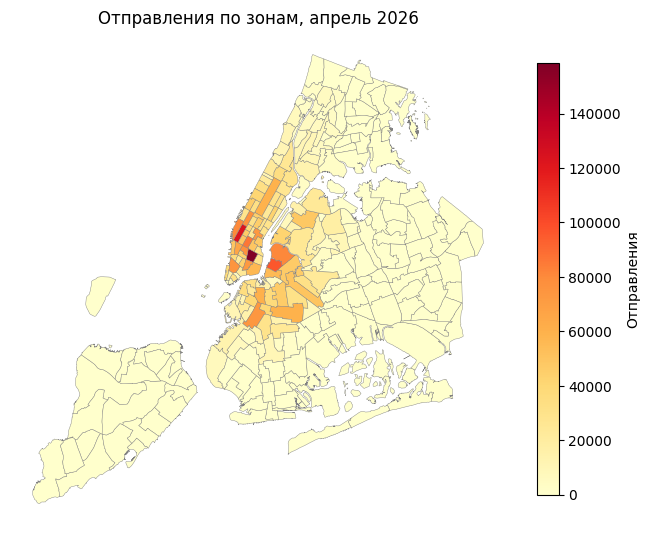

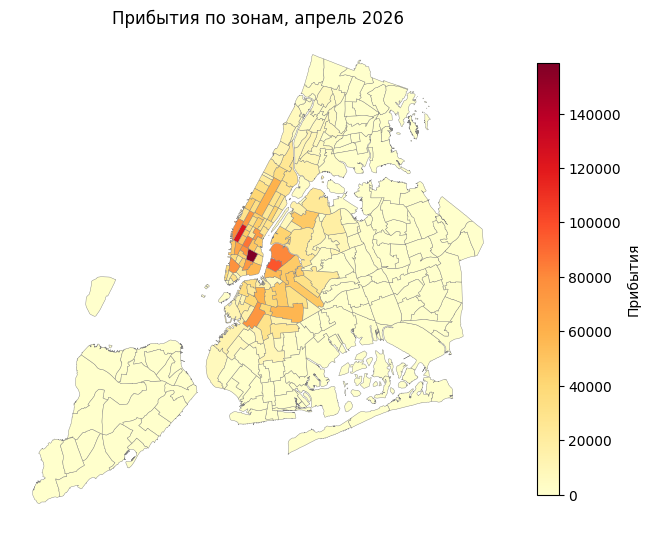

DataFrame[station_id: string, station_name: string, starts: bigint, ends: bigint, latitude: double, longitude: double]

In [6]:
counts = zone_counts.select("zone_id", "starts", "ends").toPandas()
map_data = zones_map.merge(counts, left_on="locationid", right_on="zone_id")
maximum = counts[["starts", "ends"]].max().max()

for column, title in [("starts", "Отправления"), ("ends", "Прибытия")]:
    ax = map_data.plot(
        column=column, cmap="YlOrRd", vmin=0, vmax=maximum,
        legend=True, legend_kwds={"label": title, "shrink": 0.7},
        edgecolor="gray", linewidth=0.3, figsize=(8, 8)
    )
    ax.set_title(f"{title} по зонам, апрель 2026")
    ax.set_axis_off()
    ax.figure.savefig(f"output/{column}_choropleth.png", dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(ax.figure)

zone_counts.unpersist()
station_counts.unpersist()

## Задание 2. Расстояния поездок

### 1. Расстояния поездок

Исключаем поездки с одинаковыми ID начальной и конечной станций. Строки без ID станции тоже не участвуют.
Переводим координаты в радианы и считаем расстояние по формуле гаверсинуса

In [7]:
coordinates = (
    trips.filter("start_station_id != end_station_id")
    .selectExpr(
        "radians(cast(start_lat as double)) as lat1",
        "radians(cast(start_lng as double)) as lon1",
        "radians(cast(end_lat as double)) as lat2",
        "radians(cast(end_lng as double)) as lon2"
    )
)

lat1, lon1 = F.col("lat1"), F.col("lon1")
lat2, lon2 = F.col("lat2"), F.col("lon2")
a = (
    F.sin((lat2 - lat1) / 2) ** 2
    + F.cos(lat1) * F.cos(lat2) * F.sin((lon2 - lon1) / 2) ** 2
)
distances = coordinates.select(
    (2 * 6371000 * F.asin(F.sqrt(a))).alias("distance_m")
)

### 2. Статистика расстояний

Максимум, среднее, стандартное отклонение и медиана в метрах

In [8]:
statistics = distances.agg(
    F.round(F.max("distance_m"), 2).alias("Максимум, м"),
    F.round(F.avg("distance_m"), 2).alias("Среднее, м"),
    F.round(F.stddev_pop("distance_m"), 2).alias("Станд. отклонение, м"),
    F.round(F.median("distance_m"), 2).alias("Медиана, м")
)
statistics.show()

+-----------+----------+--------------------+----------+
|Максимум, м|Среднее, м|Станд. отклонение, м|Медиана, м|
+-----------+----------+--------------------+----------+
|   27103.73|   2045.47|             1685.39|    1538.0|
+-----------+----------+--------------------+----------+



## Задание 3. Активность по времени

Используем поездки за апрель 2026 года. Отправления считаем по времени начала, прибытия — по времени завершения. Прибытия 1 мая не входят в расчёт апреля. События без ID станции пропускаем.

In [9]:
dates = trips.select(F.to_date("started_at").alias("date")).distinct()
day_count = dates.count()

starts = trips.selectExpr(
    "start_station_id as station_id", "start_station_name as station_name",
    "cast(start_lat as double) as latitude", "cast(start_lng as double) as longitude",
    "cast(started_at as timestamp) as time", "1 as starts", "0 as ends"
)
ends = trips.selectExpr(
    "end_station_id as station_id", "end_station_name as station_name",
    "cast(end_lat as double) as latitude", "cast(end_lng as double) as longitude",
    "cast(ended_at as timestamp) as time", "0 as starts", "1 as ends"
)
events = (
    starts.unionByName(ends).filter("station_id != ''")
    .withColumn("date", F.to_date("time"))
    .withColumn("period", F.floor(F.hour("time") / 6))
    .join(dates, "date")
)
stations = events.groupBy("station_id").agg(
    F.first("station_name", ignorenulls=True).alias("station_name"),
    F.avg("latitude").alias("latitude"), F.avg("longitude").alias("longitude")
).cache()
daily_counts = events.groupBy("station_id", "date", "period").agg(
    F.sum("starts").alias("starts"), F.sum("ends").alias("ends")
).cache()

### 1. Среднее количество отправлений и прибытий в день

Суммы по станции делим на 30 дней, включая дни без поездок. В выводе — первые 10 станций, значения округлены до двух знаков.

In [10]:
daily_averages = daily_counts.groupBy("station_id").agg(
    (F.sum("starts") / day_count).alias("starts"),
    (F.sum("ends") / day_count).alias("ends")
).join(stations, "station_id")

daily_averages.select(
    "station_id", "station_name",
    F.round("starts", 2).alias("starts"), F.round("ends", 2).alias("ends")
).orderBy("station_id").show(10, truncate=False)

+----------+---------------------------+------+-----+
|station_id|station_name               |starts|ends |
+----------+---------------------------+------+-----+
|1234.56   |Morgan HCT Charging        |9.4   |10.67|
|1964.01   |101 St & Fort Hamilton Pkwy|1.5   |1.5  |
|2009.04   |Shore Rd & 4 Ave           |3.83  |3.87 |
|2042.01   |4 Ave & 99 St              |3.03  |3.13 |
|2086.07   |99 St & 3 Ave              |1.77  |1.87 |
|2118.13   |Fort Hamilton Pkwy & 95 St |1.4   |1.5  |
|2127.03   |Shore Rd & 97 St           |3.43  |3.5  |
|2158.08   |4 Ave & 94 St              |2.97  |4.17 |
|2190.08   |Fort Hamilton Pkwy & 92 St |4.4   |4.43 |
|2200.07   |96 St & Marine Ave         |2.97  |3.07 |
+----------+---------------------------+------+-----+
only showing top 10 rows



### 2. Среднее по времени суток

Ночь -  00:00–05:59 

Утро - 06:00–11:59

День - 12:00–17:59

Вечер - 18:00–23:59

Отсутствующие сочетания станции и периода заполняем нулями

In [11]:
periods = spark.sql("""
    SELECT * FROM VALUES
    (0, 'Ночь 00:00–05:59'), (1, 'Утро 06:00–11:59'),
    (2, 'День 12:00–17:59'), (3, 'Вечер 18:00–23:59')
    AS periods(period, period_name)
""")
period_names = [row.period_name for row in periods.orderBy("period").collect()]

period_averages = daily_counts.groupBy("station_id", "period").agg(
    (F.sum("starts") / day_count).alias("starts"),
    (F.sum("ends") / day_count).alias("ends")
)
period_averages = (
    stations.crossJoin(periods)
    .join(period_averages, ["station_id", "period"], "left")
    .fillna(0, subset=["starts", "ends"])
)
period_averages.orderBy("station_id", "period").select(
    "station_id", "station_name", "period_name",
    F.round("starts", 2).alias("starts"), F.round("ends", 2).alias("ends")
).show(12)

+----------+--------------------+-----------------+------+----+
|station_id|        station_name|      period_name|starts|ends|
+----------+--------------------+-----------------+------+----+
|   1234.56| Morgan HCT Charging| Ночь 00:00–05:59|  0.37| 0.7|
|   1234.56| Morgan HCT Charging| Утро 06:00–11:59|   4.0|3.67|
|   1234.56| Morgan HCT Charging| День 12:00–17:59|  2.23|2.47|
|   1234.56| Morgan HCT Charging|Вечер 18:00–23:59|   2.8|3.83|
|   1964.01|101 St & Fort Ham...| Ночь 00:00–05:59|   0.0| 0.0|
|   1964.01|101 St & Fort Ham...| Утро 06:00–11:59|  0.23|0.13|
|   1964.01|101 St & Fort Ham...| День 12:00–17:59|  0.77|0.87|
|   1964.01|101 St & Fort Ham...|Вечер 18:00–23:59|   0.5| 0.5|
|   2009.04|    Shore Rd & 4 Ave| Ночь 00:00–05:59|  0.13| 0.2|
|   2009.04|    Shore Rd & 4 Ave| Утро 06:00–11:59|  0.93|0.53|
|   2009.04|    Shore Rd & 4 Ave| День 12:00–17:59|   1.6|1.87|
|   2009.04|    Shore Rd & 4 Ave|Вечер 18:00–23:59|  1.17|1.27|
+----------+--------------------+-------

### 3. Среднее по периодам в среду и воскресенье

В апреле 5 сред и 4 воскресенья. В Spark воскресенье имеет номер 1, среда — 4.

In [12]:
weekday_days = (
    dates.withColumn("weekday", F.dayofweek("date"))
    .groupBy("weekday").agg(F.count("*").alias("days"))
    .filter("weekday IN (1, 4)")
    .withColumn("day_name", F.when(F.col("weekday") == 1, "Воскресенье").otherwise("Среда"))
)

weekday_totals = (
    daily_counts.withColumn("weekday", F.dayofweek("date"))
    .filter("weekday IN (1, 4)")
    .groupBy("station_id", "period", "weekday")
    .agg(F.sum("starts").alias("starts"), F.sum("ends").alias("ends"))
)
weekday_averages = (
    stations.crossJoin(periods).crossJoin(weekday_days)
    .join(weekday_totals, ["station_id", "period", "weekday"], "left")
    .fillna(0, subset=["starts", "ends"])
    .withColumn("starts", F.col("starts") / F.col("days"))
    .withColumn("ends", F.col("ends") / F.col("days"))
)
weekday_averages.orderBy("station_id", "weekday", "period").select(
    "station_id", "station_name", "day_name", "period_name",
    F.round("starts", 2).alias("starts"), F.round("ends", 2).alias("ends")
).show(weekday_averages.count())

+------------+--------------------+-----------+-----------------+------+------+
|  station_id|        station_name|   day_name|      period_name|starts|  ends|
+------------+--------------------+-----------+-----------------+------+------+
|     1234.56| Morgan HCT Charging|Воскресенье| Ночь 00:00–05:59|   0.5|  0.75|
|     1234.56| Morgan HCT Charging|Воскресенье| Утро 06:00–11:59|   2.0|   4.0|
|     1234.56| Morgan HCT Charging|Воскресенье| День 12:00–17:59|   3.5|  1.75|
|     1234.56| Morgan HCT Charging|Воскресенье|Вечер 18:00–23:59|  2.25|  4.75|
|     1234.56| Morgan HCT Charging|      Среда| Ночь 00:00–05:59|   0.0|   0.2|
|     1234.56| Morgan HCT Charging|      Среда| Утро 06:00–11:59|   5.2|   4.6|
|     1234.56| Morgan HCT Charging|      Среда| День 12:00–17:59|   2.4|   2.4|
|     1234.56| Morgan HCT Charging|      Среда|Вечер 18:00–23:59|   3.2|   3.2|
|     1964.01|101 St & Fort Ham...|Воскресенье| Ночь 00:00–05:59|   0.0|   0.0|
|     1964.01|101 St & Fort Ham...|Воскр

### 4. Тепловые карты по времени суток

Показываем средние из пункта 2: сначала отправления, затем прибытия.

In [14]:
points = period_averages.select("period", "latitude", "longitude", "starts", "ends").collect()
maximum = max(max(point.starts, point.ends) for point in points)

for column, title in [("starts", "Отправления"), ("ends", "Прибытия")]:
    frames = [[], [], [], []]
    for point in points:
        if point[column] > 0:
            frames[point.period].append([
                point.latitude, point.longitude, point[column] / maximum
            ])

    time_map = folium.Map(location=[40.73, -73.98], zoom_start=11, tiles="OpenStreetMap")
    HeatMapWithTime(frames, index=period_names, name=title).add_to(time_map)
    folium.LayerControl().add_to(time_map)
    time_map.save(f"output/{column}_heatmap.html")
    display(time_map)

daily_counts.unpersist()
stations.unpersist()
trips.unpersist()

DataFrame[start_station_id: string, start_station_name: string, start_lat: string, start_lng: string, end_station_id: string, end_station_name: string, end_lat: string, end_lng: string, started_at: string, ended_at: string]